# Rabi Experiment

In [1]:
from nqct.utils.QuantumSession import QuantumSession

api_key = input('Enter API Key') #<---PASTE_API_KEY_HERE instead of the input(...)
qs = QuantumSession(api_key=api_key, storage_path='temp/')
qs.list_backends();
#Copy over the desired backend from the given list
qs.select_backend('quantware_soprano_d2')

,Name,Backend ID,Qubits
0,Qiskit Aer Simulator,aer_simulator,5
1,QuantWare Soprano D2,quantware_soprano_d2,7


The Rabi experiment maps qubit rotations. Typically, we choose that rotation axis to be the x-axis and measure the z-population over different rotation angles. This is typically used as a first-pass experiment to both confirm the presence of x-axis qubit-control and to calibrate the $\pi$ and $\pi/2$ rotations.

## Simple Rabi using the pre-tuned gates

Here we use the pre-tuned gates to perform the rotations. The following script uses pure OpenQASM3:

In [2]:
my_script = r"""
OPENQASM 3;
include 'stdgates_transmon_fixed_coupler.inc';
 
bit[21] c;
qubit q;

for int m in [0:20]
{
    reset q;
    rx(2*pi/11*m) q;
    c[m] = measure q;
}
"""
qs.set_qasm(my_script)
qs.set_qreg_physical_mapping({('q',0):0})

Setup readout parameters and execute

In [3]:
qs.set_acquisition_type('DISCRIMINATION')
qs.set_averaging_type('SingleShotCounts')
qs.set_num_shots(1024)
qs.set_shot_repeat(1)
#
leRes = qs.run()

The resulting array slices over the 21 bit register measurements, each with 1024 shots (i.e. 0 or 1). So take the average on each measurement over all its shots and plot the Rabi oscillations:

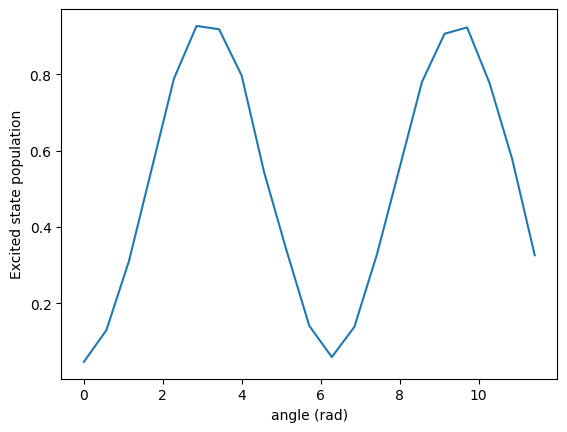

In [4]:
import numpy as np
import matplotlib.pyplot as plt

cur_arrs = leRes.get_data('c')
pops_e = np.mean(cur_arrs, axis=1)

fig, ax = plt.subplots(1); ax.set_xlabel('angle (rad)'); ax.set_ylabel('Excited state population')
ax.plot(2*np.pi/11*np.arange(21), pops_e);

## Simple Rabi using the pulse-control

Now we perform the same experiment, but using the low-level pulse control via OpenPulse constructs. We create a 30ns Gaussian pulse envelope on the qubit 0 drive line and measure the resulting population on increasing the Gaussian envelope's amplitude. The idea is that with a larger amplitude, the x-rotation rate is faster and thus, rotates further over the same 30ns time-frame.

In [5]:
my_script = r"""
OPENQASM 3;
include 'stdgates_transmon_fixed_coupler.inc';
 
bit[21] c;
qubit q;

defcal rabi_rot(float ampl) $0
{
	play(drive($0), gaussian(30ns, ampl));
}

for int m in [0:20]
{
	reset q;

	//This automatically calls our defcal as q is mapped to qubit $0.
	rabi_rot(m/21.0) q;

	c[m] = measure q;
}
"""
qs.set_qasm(my_script)
qs.set_qreg_physical_mapping({('q',0):0})

This time, let's not presume that we have calibrated the readout. Thus, let's just take in the raw IQ values integrated over 1024 shots:

In [6]:
qs.set_acquisition_type('INTEGRATION')
qs.set_averaging_type('AverageRepetitions')
qs.set_num_shots(1024)
qs.set_shot_repeat(1)

leRes = qs.run()

Notice the shape of the returned dataset. Every point has a 2D IQ value:

In [7]:
cur_arrs = np.array(leRes.get_data('c'))
cur_arrs.shape

(21, 2)

Given that we cannot really normalise this into populations yet, let's just plot the amplitude of the IQ values (not typically the optimal approach to maximise signal constrast between ground and excited states; but good enough for an initial pass) and fit the oscillations using utilities form *SQDToolz*:

0.3385535371697129

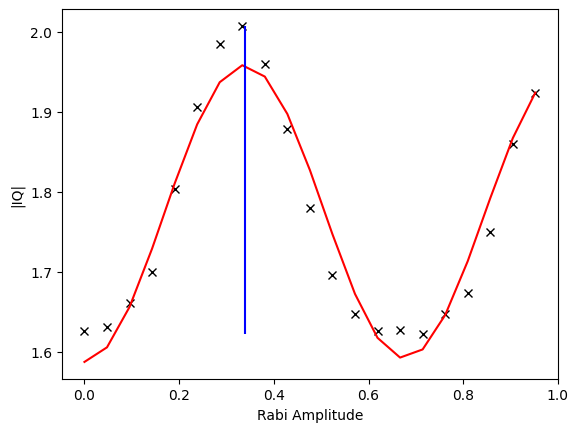

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from sqdtoolz.Utilities.DataFitting import DFitSinusoid

amplitudes = np.sqrt(cur_arrs[:,0]**2 + cur_arrs[:,1]**2)

dfit = DFitSinusoid()
dpkt = dfit.get_fitted_plot(np.arange(21)/21, amplitudes)
pi_amplitude = float(0.5/dpkt['frequency'])
#
plt.vlines([pi_amplitude], np.min(amplitudes), np.max(amplitudes), 'b')
plt.xlabel('Rabi Amplitude')
plt.ylabel('|IQ|')
#
pi_amplitude

Now that we have a good estimate for the $X(\pi)$ amplitude, let's redo the Rabi and normalise the axis. The following script takes two calibration points on ground and excited states (using the estimated pi amplitude) before taking the Rabi trace. Note that we could just string-replace the $\pi$-amplitude, but we do it via the const float to demonstrate the use of const variables:

In [9]:
my_script = f"""
OPENQASM 3;
include 'stdgates_transmon_fixed_coupler.inc';
 
bit[21] c;
bit[2] calib;
qubit q;

const float rabi_pi_amplitude = {pi_amplitude};
"""

my_script += r"""
defcal rabi_rot(float ampl) $0
{
	play(drive($0), gaussian(30ns, ampl));
}

//Take calibration traces
//Ground
reset q;
calib[0] = measure q;
//Excited
reset q;
rabi_rot(rabi_pi_amplitude) q;
calib[1] = measure q;

//Perform the Rabi cycle
for int m in [0:20]
{
	reset q;

	//This automatically calls our defcal as q is mapped to qubit $0.
	rabi_rot(m/21.0) q;

	c[m] = measure q;
}
"""
qs.set_qasm(my_script)
qs.set_qreg_physical_mapping({('q',0):0})

Let's run using the same settings from before:

In [10]:
qs.set_acquisition_type('INTEGRATION')
qs.set_averaging_type('AverageRepetitions')
qs.set_num_shots(1024)
qs.set_shot_repeat(1)

leRes = qs.run()

This time we have to retrieve both the main data and the calibration data:

In [11]:
rabi_arrs = np.array(leRes.get_data('c'))
calib_arrs = np.array(leRes.get_data('calib'))
calib_arrs.shape

(2, 2)

The calibration is a bit involved as it requires one to:
- Take the calibrated IQ points for G and E: $G_c$ and $E_c$ (both in $\mathbb{R}^2$)
- Translate the Rabi data by bringing the ground point to the origin: $R_{trans} = R - G_c$
- Rotate the data by the angle produced by Ec with respect to Gc to get: $R_{rot}$
- Then divide the x-axis by $||E_c-G_c||$ and just take the x-axis value to get the population from 0 to 1

We will just use a utility in *SQDToolz* that handles all this:

0.33523631897055345

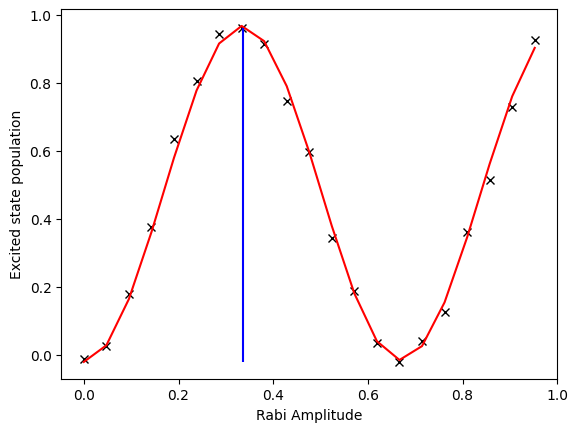

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from sqdtoolz.Utilities.DataFitting import DFitSinusoid
from sqdtoolz.Utilities.DataIQNormalise import DataIQNormalise

#The class accepts multiple sampled points for G and E, since we only have 1, we nest the array...
dNorm = DataIQNormalise([calib_arrs[0]], [calib_arrs[1]])
normalised_data = dNorm.normalise_data(rabi_arrs)

dfit = DFitSinusoid()
dpkt = dfit.get_fitted_plot(np.arange(21)/21, normalised_data)
pi_amplitude = float(0.5/dpkt['frequency'])
#
plt.vlines([pi_amplitude], np.min(normalised_data), np.max(normalised_data), 'b')
plt.xlabel('Rabi Amplitude')
plt.ylabel('Excited state population')
#
pi_amplitude

Notice how the Rabi cycle now looks clean and the excited state population goes between 0 and 1.